Imports and paths

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
raw_data_dir = ROOT / "data" / "raw"

Loading the data

In [3]:
competitions = pd.read_csv(raw_data_dir / "competitions.csv.gz")
clubs = pd.read_csv(raw_data_dir / "clubs.csv.gz")
valuations = pd.read_csv(raw_data_dir / "player_valuations.csv.gz")
players = pd.read_csv(raw_data_dir / "players.csv.gz")
appearances = pd.read_csv(raw_data_dir / "appearances.csv.gz")

The Premier League 2025-26 scope: clubs, players and appearances

In [4]:
pl_clubs = clubs[(clubs["domestic_competition_id"] == "GB1") & (clubs["last_season"] == 2025)]

pl_players = players[
    players["current_club_id"].isin(pl_clubs["club_id"]) & (players["last_season"] == 2025)
].merge(pl_clubs[["club_id", "name"]].rename(columns={"name": "club"}), left_on="current_club_id", right_on="club_id")

pl_appearances = appearances.merge(pl_players[["player_id", "name", "club"]], on="player_id")

## Data quality checks

Each check counts the number of problematic rows (0 = OK).
The scope of the analysis is limited to the Premier League 2025/2026 season.

In [5]:
all_player_ids = set(players["player_id"]) 
all_valuation_pids = valuations["player_id"]

competitions = competitions[competitions["competition_id"] == "GB1"]
clubs = clubs[(clubs["domestic_competition_id"] == "GB1") & (clubs["last_season"] == 2025)]
appearances = appearances[(appearances["competition_id"] == "GB1") & (appearances["date"] >= "2025-07-01") & (appearances["date"] < "2026-07-01")]
players = players[players["current_club_id"].isin(clubs["club_id"]) & (players["last_season"] == 2025)]
valuations = valuations[valuations["player_id"].isin(players["player_id"])]

results = []

def check(table, description, n_bad, n_total):
    n_bad = pd.Series(n_bad).sum()
    results.append({"table": table, "check": description, "n_bad": int(n_bad),
                    "pct": round(100 * n_bad / n_total, 2), "status": "OK" if n_bad == 0 else "CHECK"})


for name, df, key in [("competitions", competitions, "competition_id"), ("clubs", clubs, "club_id"),
                      ("players", players, "player_id"), ("appearances", appearances, "appearance_id")]:
    
    check(name, "duplicated rows", df.duplicated().sum(), len(df))
    check(name, f"duplicated {key}", df[key].duplicated().sum(), len(df))

check("player_valuations", "duplicated rows", valuations.duplicated().sum(), len(valuations))

check("player_valuations", "player_id not in players", ~all_valuation_pids.isin(all_player_ids), len(all_valuation_pids))
check("appearances", "player_id not in players", ~appearances["player_id"].isin(all_player_ids), len(appearances))
check("clubs", "domestic_competition_id not in competitions", ~clubs["domestic_competition_id"].isin(competitions["competition_id"]), len(clubs))

check("players", "position missing / 'Missing'", players["position"].isna() | (players["position"] == "Missing"), len(players))
check("players", "market_value_in_eur < 0", players["market_value_in_eur"] < 0, len(players))
check("players", "market_value_in_eur missing", players["market_value_in_eur"].isna(), len(players))
check("players", "height_in_cm outside [150, 220]", ~players["height_in_cm"].dropna().between(150, 220), players["height_in_cm"].notna().sum())
check("player_valuations", "market_value_in_eur <= 0", valuations["market_value_in_eur"] <= 0, len(valuations))
check("appearances", "minutes_played outside [0, 90]", ~appearances["minutes_played"].between(0, 90), len(appearances))
check("appearances", "negative goals / assists / cards",
      (appearances[["goals", "assists", "yellow_cards", "red_cards"]] < 0).any(axis=1), len(appearances))

# 4. Dates
dob = pd.to_datetime(players["date_of_birth"], errors="coerce")
check("players", "age outside [14, 50] (valued players)", ~((pd.Timestamp.today() - dob).dt.days / 365.25).dropna().between(14, 50), dob.notna().sum())
for name, df in [("player_valuations", valuations), ("appearances", appearances)]:
    d = pd.to_datetime(df["date"], errors="coerce")
    check(name, "date unparsable or in the future", d.isna() | (d > pd.Timestamp.today()), len(df))

pd.DataFrame(results)

,table,check,n_bad,pct,status
0,competitions,duplicated rows,0,0.00,OK
1,competitions,duplicated competition_id,0,0.00,OK
2,clubs,duplicated rows,0,0.00,OK
3,clubs,duplicated club_id,0,0.00,OK
4,players,duplicated rows,0,0.00,OK
5,players,duplicated player_id,0,0.00,OK
6,appearances,duplicated rows,0,0.00,OK
7,appearances,duplicated appearance_id,0,0.00,OK
8,player_valuations,duplicated rows,0,0.00,OK
9,player_valuations,player_id not in players,0,0.00,OK


The appearances without a matching player: these players played for a Premier League club in 2025-26 but their current club is somewhere else (they left), so they are not in the filtered players table.

In [6]:
orphans = appearances[~appearances["player_id"].isin(players["player_id"])]
print(f"{len(orphans)} appearances, {orphans['player_id'].nunique()} players")
orphans.groupby("player_name").size().sort_values(ascending=False).head()

520 appearances, 38 players


player_name
Yéremy Pino       34
Tolu Arokodare    33
Senne Lammens     32
Álex Jiménez      31
Xavi Simons       28
dtype: int64

The players without a market value: how much do they play?

In [7]:
no_value = players[players["market_value_in_eur"].isna()]
played = appearances[appearances["player_id"].isin(no_value["player_id"])]
print(f"{len(no_value)} players without value, {played['player_id'].nunique()} of them played")
played_players = no_value[no_value["player_id"].isin(played["player_id"])].merge(
    clubs[["club_id", "name"]].rename(columns={"name": "club"}), left_on="current_club_id", right_on="club_id"
)
played_players["age"] = ((pd.Timestamp.today() - pd.to_datetime(played_players["date_of_birth"])).dt.days / 365.25).astype(int)
played_players["minutes"] = played_players["player_id"].map(played.groupby("player_id")["minutes_played"].sum())

played_players[["name", "club", "age", "minutes"]].sort_values("minutes", ascending=False)

131 players without value, 13 of them played


,name,club,age,minutes
9,Jesse Derry,Chelsea FC,19,45
2,Shea Lacey,Manchester United,19,40
4,George Hemmings,Aston Villa,19,25
5,Divine Mukasa,Manchester City,19,25
6,Tyler Fletcher,Manchester United,19,17
12,Jerome Abbey,Wolverhampton Wanderers,17,16
0,Dan Neil,Sunderland AFC,24,13
8,Sean Neave,Newcastle United,19,13
7,Tom Edozie,Wolverhampton Wanderers,20,12
11,Joél Drakes-Thomas,Crystal Palace,17,7


These are mostly players coming from the youth academy, who have not yet played in the Premier League and therefore do not have a market value.

Coverage of the data: 20 clubs, 38 games per club, and a valuation at the two dates used in the analysis

In [8]:
date_1 = "2025-08-15"
date_2 = "2026-06-03"

games_per_club = appearances.groupby("player_club_id")["game_id"].nunique()
print(f"{len(games_per_club)} clubs, {games_per_club.min()} to {games_per_club.max()} games per club")

for date in (date_1, date_2):
    n = valuations[valuations["date"] <= date]["player_id"].nunique()
    print(f"{date}: {n} / {len(players)} players have a valuation")

20 clubs, 38 to 38 games per club
2025-08-15: 584 / 729 players have a valuation
2026-06-03: 598 / 729 players have a valuation


Transfermarkt does not update the market values every day, but in waves: the dates of the season with more than 100 valuations.

In [9]:
season_valuations = valuations[valuations["date"] >= "2025-07-01"]
updates = season_valuations["date"].value_counts().sort_index()
updates[updates > 100]

date
2025-10-17    236
2025-12-09    508
2026-03-09    214
2026-06-03    505
Name: count, dtype: int64

The update of 3 June 2026 is the first one after the end of the season (24 May 2026), so it is the one that reflects the 2025-26 season. A value taken on 24 May would be the one of 9 March, without the last two and a half months of the season.

Plausibility check over time: the mean per player appearance should be stable from one season to the next.

In [10]:
# The audit cells above filtered `appearances` and `clubs` to 2025-26, so reload the raw files.
all_appearances = pd.read_csv(raw_data_dir / "appearances.csv.gz", parse_dates=["date"])
all_clubs = pd.read_csv(raw_data_dir / "clubs.csv.gz")

def get_season_appearances(start_year) :
    start, end = f"{start_year}-08-01", f"{start_year+1}-05-31"
    season = (
        all_appearances[
            (all_appearances["competition_id"] == "GB1")
            & all_appearances["date"].between(start, end)
        ]
        .merge(
            all_clubs[["club_id", "name"]].rename(columns={"name": "club"}),
            how="left",
            left_on="player_club_id",
            right_on="club_id",
            validate="many_to_one",
        )
        .sort_values("date")
    )
    return season 

get_season_appearances(2022)[
    ["yellow_cards", "red_cards", "goals", "assists", "minutes_played"]
].describe()



,yellow_cards,red_cards,goals,assists,minutes_played
count,11345.000000,11345.000000,11345.000000,11345.000000,11345.000000
mean,0.122257,0.001498,0.091582,0.066637,66.259586
std,0.330810,0.038683,0.322500,0.267482,31.325080
min,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,45.000000
50%,0.000000,0.000000,0.000000,0.000000,88.000000
75%,0.000000,0.000000,0.000000,0.000000,90.000000
max,2.000000,1.000000,3.000000,3.000000,90.000000


In [11]:
stats_columns = ["yellow_cards", "red_cards", "goals", "assists", "minutes_played"]

describe_by_season = {}
for start_year in range(2012, 2026):
    season_label = f"{start_year}-{str(start_year + 1)[-2:]}"
    season = get_season_appearances(start_year)
    if season.empty:
        print(f"{season_label}: no Premier League appearances in the dataset, skipped")
        continue
    describe_by_season[season_label] = season[stats_columns].describe()


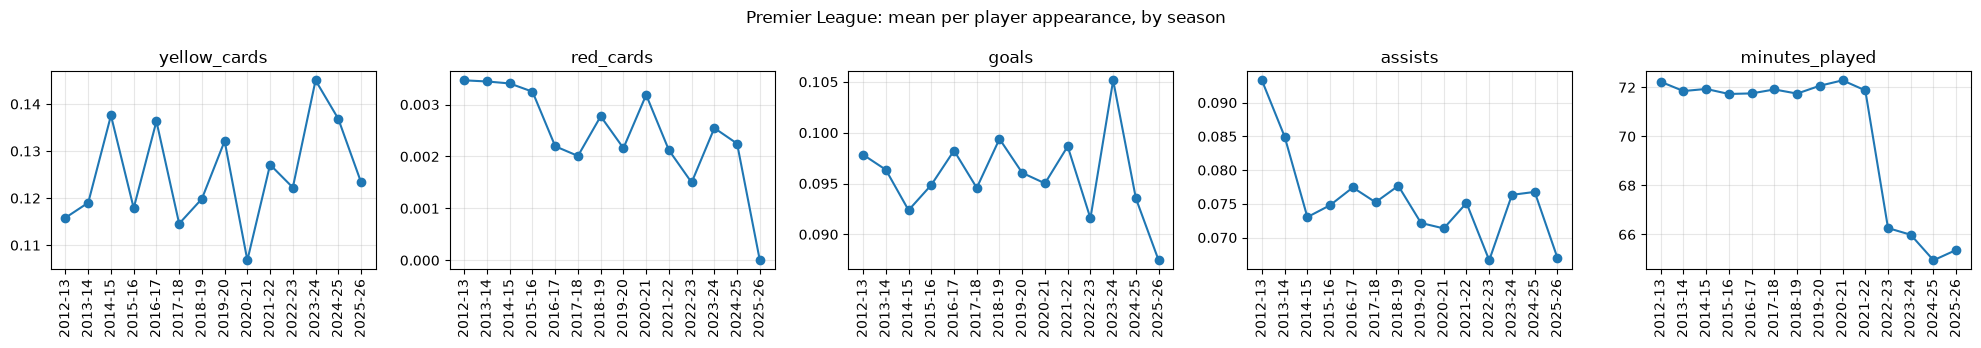

In [12]:
means = pd.DataFrame({season: d.loc["mean"] for season, d in describe_by_season.items()}).T

fig, axes = plt.subplots(1, len(stats_columns), figsize=(4 * len(stats_columns), 3.5))
for ax, stat in zip(axes, stats_columns):
    ax.plot(means.index, means[stat], marker="o")
    ax.set_title(stat)
    ax.tick_params(axis="x", rotation=90)
    ax.grid(alpha=0.3)
fig.suptitle("Premier League: mean per player appearance, by season")
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "mean_stats_appearances_per_season.png", dpi=150)
plt.show()

What we see on the figure:

- **minutes_played** drops from about 72 to 66 minutes in 2022-23: this is the season the Premier League moved from three to five substitutions per game, so more players share the minutes.
- **goals** peaks in 2023-24: it was a record season for the number of goals in the Premier League.
- **red_cards** falls to 0 in 2025-26, which is not possible over a full season. Let's count the red cards per season.

In [13]:
red_cards_per_season = pd.DataFrame({
    f"{start_year}-{str(start_year + 1)[-2:]}": {
        "red_cards": get_season_appearances(start_year)["red_cards"].sum(),
        "two_yellow_cards": (get_season_appearances(start_year)["yellow_cards"] == 2).sum(),
    }
    for start_year in range(2021, 2026)
}).T

red_cards_per_season

,red_cards,two_yellow_cards
2021-22,22,21
2022-23,17,12
2023-24,29,29
2024-25,26,26
2025-26,0,0


No red card and no second yellow card in 2025-26, against about 25 per season before: the red cards are not filled in the dataset for this season.

Players who played in the Premier League in 2025-26, per club: a club uses about 25 to 30 players over a season.

In [14]:
players_per_club = appearances.groupby("player_club_id")["player_id"].nunique()
print(f"{appearances['player_id'].nunique()} players, {players_per_club.min()} to {players_per_club.max()} per club")

537 players, 22 to 32 per club


## Conclusion

- The processed dataset (src/make_dataset.py) keeps only the players who played in the Premier League in 2025-26, with their last Premier League club (even if they left in January). The players who were in a squad but never played are removed. This gives 22 to 32 players per club, which matches a real Premier League season.
- The market value at the end of the season is the update of 3 June 2026, the first one after the last game of the season.
- The players without a market value are dropped. They are young players who almost never play.
- Only the players with a valuation at both dates are compared.
- The red cards are missing for the 2025-26 season, so they are not used in the analysis.
- The drop of the minutes played since 2022-23 is explained by the five substitutions rule.
- All the other checks are OK.